# Gilt liquidity stress test

**Question:** how large a rise in gilt yields can a hypothetical pension fund absorb before it runs short of cash to meet collateral calls?

The method follows a threshold-based Monte Carlo workflow. Simulate many possible outcomes, run each one through a model, and count how often a threshold is crossed. Here the outcomes are paths of a long-dated gilt yield, and the threshold is the fund's cash buffer.

All fund figures are **hypothetical** and chosen for illustration. Nothing here describes a real pension scheme or LDI fund.

## 1. Motivation

A defined benefit (DB) pension fund promises to pay pensions decades into the future. It values those liabilities by discounting them, typically with long-dated gilt or swap rates. When long-term yields fall, the present value of the liabilities rises, so the fund's funding position worsens even if nothing else changes. To protect against this, many funds **hedge their interest-rate exposure**. They hold long-dated gilts, often with extra exposure gained through gilt repo, and receive-fixed interest rate swaps, frequently through liability-driven investment (LDI) funds. These positions gain value when yields fall, offsetting the rise in liabilities.

The hedge works in both directions. When yields **rise**, the hedge loses value. Swap counterparties and repo lenders then require the fund to post **collateral**, usually cash, often within a day. On paper the fund may be no worse off, because the value of its long-term liabilities falls at the same time. But the liability gain is not cash, while the collateral call is. A fund that runs out of liquid assets may have to sell gilts into a falling market. In September 2022 this kind of forced selling pushed yields higher still and led the Bank of England to intervene in the gilt market.

This notebook models only the **cash need of one hypothetical fund**. It does not model liabilities, other funds, or the feedback from forced sales to market prices.

**Model, in one line:** if the yield has risen by $\Delta y$ basis points (bp) since day 0, the collateral the fund must have posted is
$$
\text{Collateral}(\Delta y) = s \cdot \max(\Delta y, 0),
$$
where $s$ is the hedge's loss per basis point (its PV01, the change in value for a 1bp move). The fund breaches when the collateral required exceeds its cash buffer $B$, and the shortfall is $\max(\text{Collateral} - B, 0)$. The yield rise the buffer can absorb, the **headroom**, is $B/s$ basis points.

In [1]:
# Imports and settings used throughout
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 12
FIG_DIR = Path('figures')
FIG_DIR.mkdir(exist_ok=True)

def gbp(x):
    '''Format a number of pounds, e.g. 1234567 -> "£1,234,567".'''
    return f'£{x:,.0f}'

## 2. One shock, worked by hand

Hypothetical fund: a **£1m cash buffer** and a hedge that loses **£20,000 per basis point** of rising yields.

By hand:
* Headroom $= £1{,}000{,}000 / £20{,}000 = 50$ bp.
* A **50 bp** rise needs $50 \times £20{,}000 = £1{,}000{,}000$ of collateral. This uses up the whole buffer, with no shortfall.
* A **60 bp** rise needs $60 \times £20{,}000 = £1{,}200{,}000$, leaving a shortfall of **£200,000**.

In [2]:
# Section 2: the collateral model for a single yield shock
BUFFER = 1_000_000        # £ cash buffer (hypothetical)
SENS = 20_000             # £ lost on the hedge per 1bp rise in yields (hypothetical)


def collateral_required(dy_bp, sens=SENS):
    '''Collateral the fund must have posted after a cumulative yield change of dy_bp basis points.
    Losses are fully collateralised; if yields fall back, collateral is returned (never below zero).'''
    return sens * np.maximum(dy_bp, 0)


def shortfall(dy_bp, buffer=BUFFER, sens=SENS):
    '''Cash shortfall: collateral required in excess of the cash buffer (zero if the buffer covers it).'''
    return np.maximum(collateral_required(dy_bp, sens) - buffer, 0)


shocks = np.array([0, 25, 50, 60, 100])
table = pd.DataFrame({
    'Yield rise (bp)': shocks,
    'Collateral required': [gbp(collateral_required(d)) for d in shocks],
    'Buffer left': [gbp(max(BUFFER - collateral_required(d), 0)) for d in shocks],
    'Shortfall': [gbp(shortfall(d)) for d in shocks],
})
print(f'Headroom = buffer / sensitivity = {BUFFER / SENS:.0f} bp')
display(table.style.hide(axis='index'))

# Check against the hand-worked numbers
assert collateral_required(50) == 1_000_000 and shortfall(50) == 0
assert shortfall(60) == 200_000
print('Hand-worked example reproduced: 50bp exhausts the buffer, 60bp leaves a £200,000 shortfall.')

Headroom = buffer / sensitivity = 50 bp


Yield rise (bp),Collateral required,Buffer left,Shortfall
0,£0,"£1,000,000",£0
25,"£500,000","£500,000",£0
50,"£1,000,000",£0,£0
60,"£1,200,000",£0,"£200,000"
100,"£2,000,000",£0,"£1,000,000"


Hand-worked example reproduced: 50bp exhausts the buffer, 60bp leaves a £200,000 shortfall.


## 3. Simulate yield paths

We now simulate many possible paths for one long-dated gilt yield over a **10-business-day horizon**.

Baseline assumptions, all explicitly hypothetical:
* Daily yield changes are **independent and normally distributed** with mean 0.
* Baseline daily volatility $\sigma = 8$ bp/day. For comparison, a high-volatility case uses $\sigma = 15$ bp/day.
* Each path starts at a cumulative change of 0 on day 0. Day $t$ holds the sum of the first $t$ daily changes.

We draw the standard normal shocks **once**, with a fixed seed, and scale them by $\sigma$. Every scenario below, whatever its buffer, hedge size or volatility, therefore uses the same underlying random draws (*common random numbers*). Differences between scenarios come from the assumptions, not from simulation noise.

Std of day-10 change: simulated 25.25 bp, theory 25.30 bp


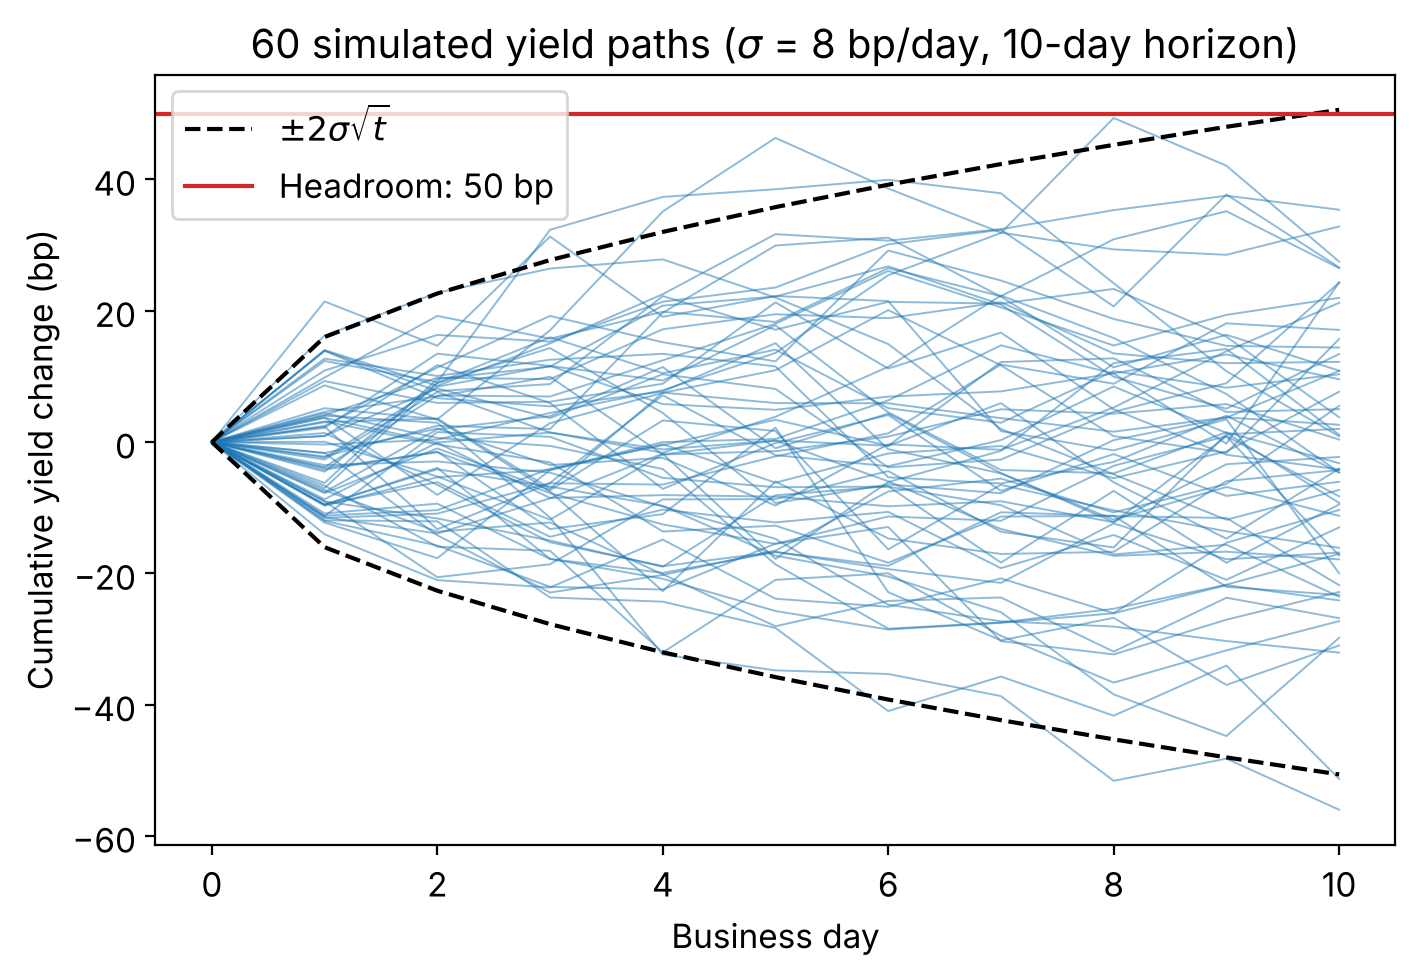

In [3]:
# Section 3: simulate cumulative yield-change paths (in bp) over a 10-business-day horizon
N_PATHS = 100_000
HORIZON = 10                 # business days
SIGMA_BASE = 8.0             # bp per day (hypothetical baseline)
SIGMA_HIGH = 15.0            # bp per day (hypothetical high-volatility case)

rng = np.random.default_rng(2022)
Z = rng.standard_normal((N_PATHS, HORIZON))      # drawn once, reused everywhere


def simulate_paths(sigma, z=Z):
    '''Cumulative yield change (bp) on days 0..H for each path: shape (n_paths, H + 1), starting at 0.'''
    daily_changes = sigma * z
    cumulative = np.cumsum(daily_changes, axis=1)
    return np.hstack([np.zeros((z.shape[0], 1)), cumulative])


paths_base = simulate_paths(SIGMA_BASE)
days = np.arange(HORIZON + 1)

# Sanity check: day-10 changes should have standard deviation sigma * sqrt(10)
print(f'Std of day-{HORIZON} change: simulated {paths_base[:, -1].std():.2f} bp, '
      f'theory {SIGMA_BASE * np.sqrt(HORIZON):.2f} bp')

fig, ax = plt.subplots()
ax.plot(days, paths_base[:60].T, color='tab:blue', lw=0.7, alpha=0.5)
ax.plot(days, 2 * SIGMA_BASE * np.sqrt(days), 'k--', label=r'$\pm 2\sigma\sqrt{t}$')
ax.plot(days, -2 * SIGMA_BASE * np.sqrt(days), 'k--')
ax.axhline(BUFFER / SENS, color='tab:red', label=f'Headroom: {BUFFER / SENS:.0f} bp')
ax.set_xlabel('Business day')
ax.set_ylabel('Cumulative yield change (bp)')
ax.set_title(f'60 simulated yield paths ($\\sigma$ = {SIGMA_BASE:.0f} bp/day, {HORIZON}-day horizon)')
ax.legend(loc='upper left')
plt.show()

## 4. Measure liquidity risk

For each path and each day, we convert the cumulative yield change into the collateral required that day. Losses are fully collateralised, and collateral is returned as losses reverse. We then record the **largest cash shortfall anywhere along the path**. Path dependence matters here. A path that rises 70 bp by day 4 and ends at +20 bp still needed £400,000 more cash than the fund had on day 4, even though the end-of-horizon position looks safe.

In [4]:
# Section 4: largest shortfall along each path, breach rate and conditional shortfall size
def max_shortfall_along_path(paths, buffer=BUFFER, sens=SENS):
    '''Largest cash shortfall (£) on any day of each path. paths: cumulative yield changes in bp.'''
    return shortfall(paths, buffer, sens).max(axis=1)


def summarise(paths, buffer=BUFFER, sens=SENS):
    '''Breach rate (with standard error) and size of the shortfall in breaching paths.'''
    worst = max_shortfall_along_path(paths, buffer, sens)
    breach = worst > 0
    p = breach.mean()
    hit = worst[breach] if breach.any() else np.array([np.nan])   # NaN if no path breaches
    return {
        'breach_rate': p,
        'std_error': np.sqrt(p * (1 - p) / len(worst)),
        'mean_shortfall_if_breach': hit.mean(),
        'median_shortfall_if_breach': np.median(hit),
        'p95_shortfall_if_breach': np.percentile(hit, 95),
        'worst': worst,
    }


res_base = summarise(paths_base)
end_only = (shortfall(paths_base[:, -1]) > 0).mean()

print(f'Baseline: buffer {gbp(BUFFER)}, hedge {gbp(SENS)}/bp, sigma {SIGMA_BASE:.0f} bp/day, '
      f'{HORIZON}-business-day horizon, {N_PATHS:,} paths')
print(f'  Share of paths that breach the buffer at any point: {res_base["breach_rate"]:.2%} '
      f'(± {1.96 * res_base["std_error"]:.2%}, 95% CI)')
print(f'  Share breaching if we only looked at day {HORIZON}:    {end_only:.2%}')
print(f'  Shortfall when a breach occurs: median {gbp(res_base["median_shortfall_if_breach"])}, '
      f'mean {gbp(res_base["mean_shortfall_if_breach"])}, '
      f'95th percentile {gbp(res_base["p95_shortfall_if_breach"])}')

# Analytic cross-check (reflection principle for continuous Brownian motion):
# P(max over [0, H] of the yield change > h) = 2 * (1 - Phi(h / (sigma * sqrt(H)))).
# Daily monitoring checks fewer points, so this is an upper bound on the simulated rate.
h = BUFFER / SENS
approx = 2 * norm.sf(h / (SIGMA_BASE * np.sqrt(HORIZON)))
print(f'  Continuous-time approximation (upper bound): {approx:.2%}')

Baseline: buffer £1,000,000, hedge £20,000/bp, sigma 8 bp/day, 10-business-day horizon, 100,000 paths
  Share of paths that breach the buffer at any point: 3.29% (± 0.11%, 95% CI)
  Share breaching if we only looked at day 10:    2.45%
  Shortfall when a breach occurs: median £134,738, mean £179,674, 95th percentile £503,899
  Continuous-time approximation (upper bound): 4.81%


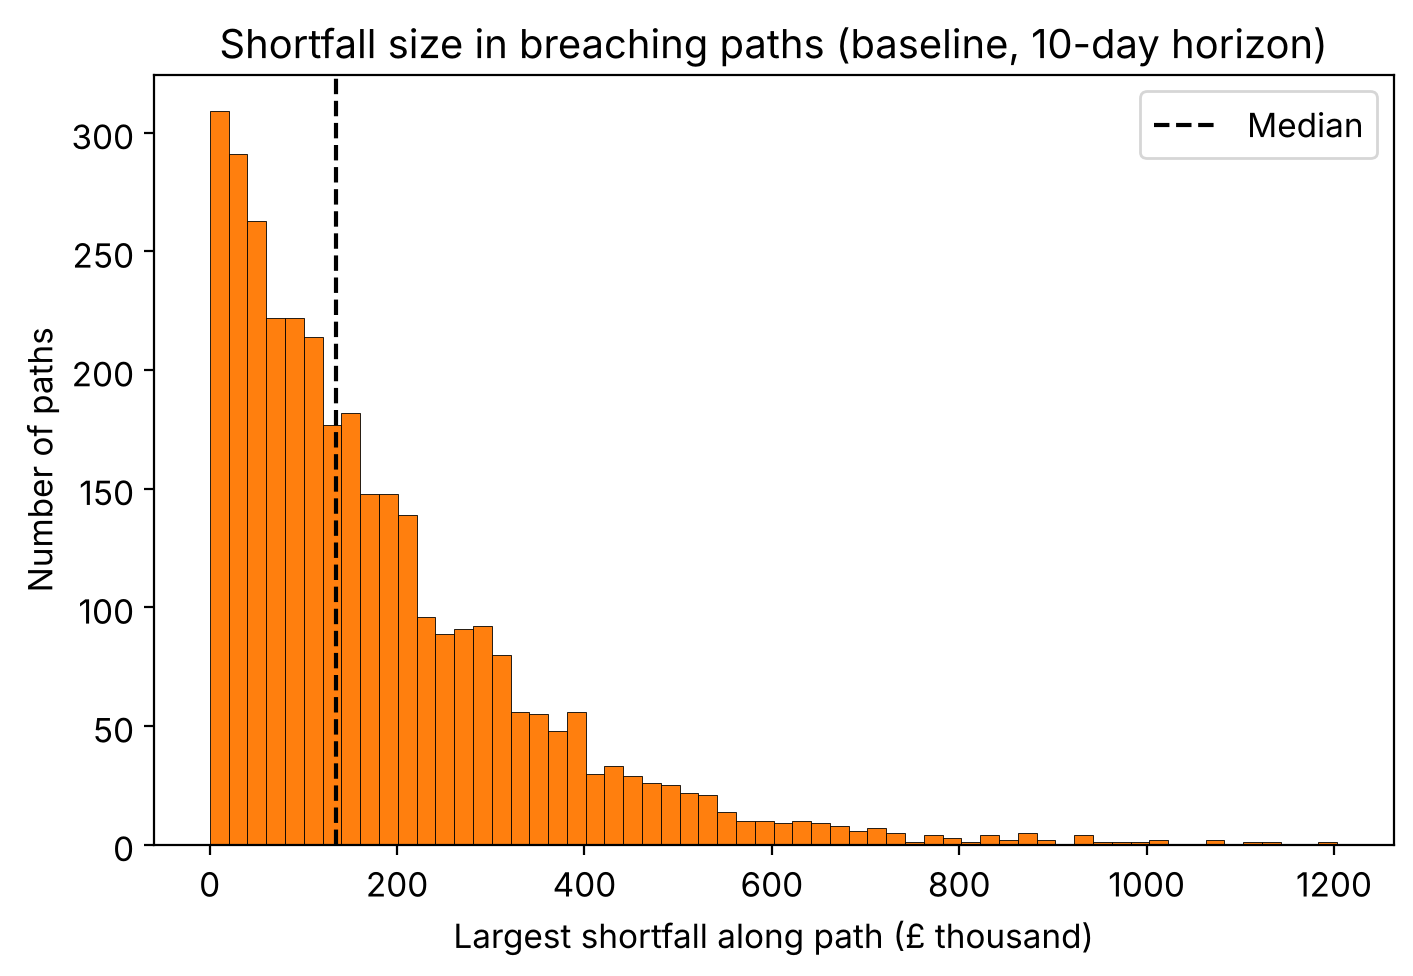

In [5]:
# Section 4: distribution of the worst shortfall in paths that breach
worst = res_base['worst']
plt.hist(worst[worst > 0] / 1e3, bins=60, color='tab:orange', edgecolor='k', lw=0.3)
plt.axvline(res_base['median_shortfall_if_breach'] / 1e3, color='k', ls='--', label='Median')
plt.xlabel('Largest shortfall along path (£ thousand)')
plt.ylabel('Number of paths')
plt.title(f'Shortfall size in breaching paths (baseline, {HORIZON}-day horizon)')
plt.legend()
plt.show()

Under the baseline, about 3.3% of 10-day paths push collateral needs past the £1m buffer at some point. Looking only at day 10 would give 2.5% and miss about a quarter of the breaches, because those paths fall back before the end of the horizon. The shortfall distribution is skewed. The median breach needs about £135,000 more cash, but 1 in 20 breaching paths needs more than £500,000. The simulated rate is below the continuous-time bound of 4.8%, as expected, because daily monitoring misses crossings that happen between observation days. This parallels the epidemiology project, where the simulated probability of a major outbreak was checked against the analytic estimate $1 - 1/R_0$.

## 5. Test sensitivity

Next we vary the cash buffer while keeping the simulated shocks fixed, and repeat for the high-volatility case. A path breaches a buffer $B$ exactly when $s \cdot \max_t \Delta y_t > B$. So we only need each path's maximum cumulative rise, and we can then evaluate every buffer size on the same paths.

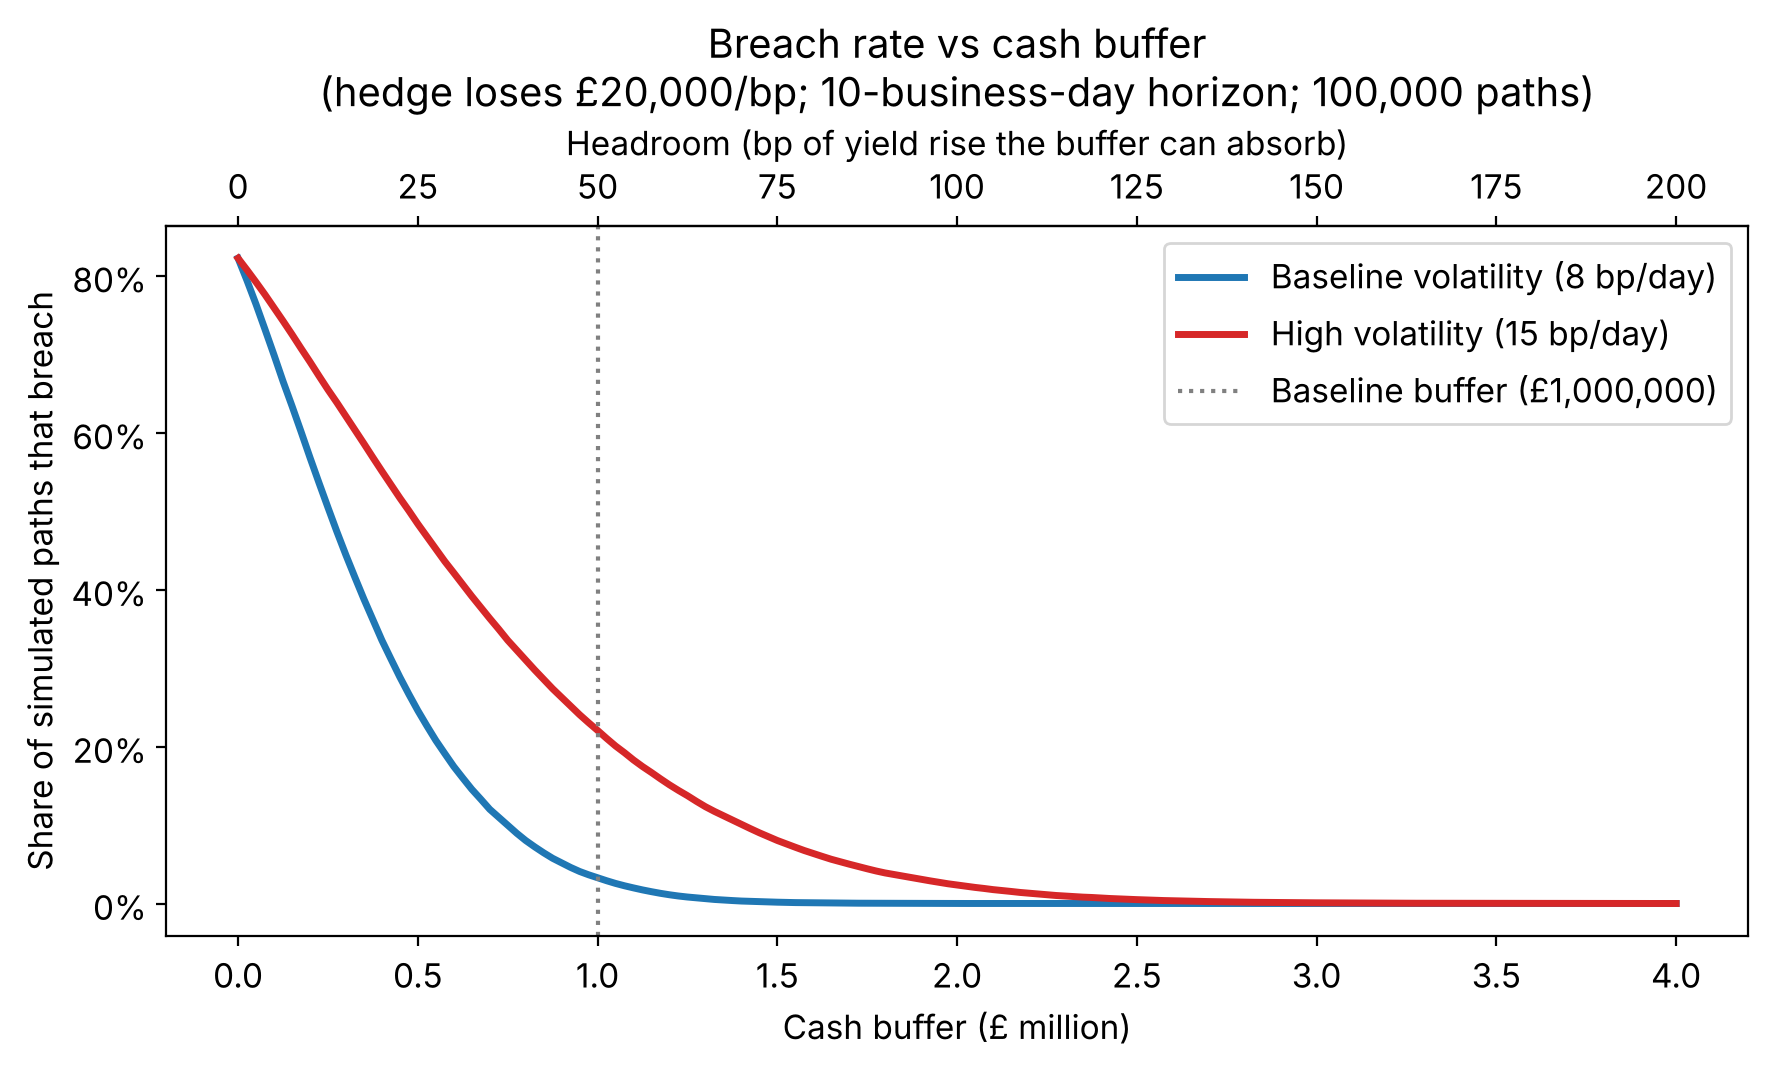

Buffer,Headroom (bp),Volatility,Horizon,Breach rate,Median shortfall if breach
"£500,000",25.000000,8 bp/day,10 business days,24.60%,"£194,307"
"£500,000",25.000000,15 bp/day,10 business days,48.38%,"£447,269"
"£1,000,000",50.000000,8 bp/day,10 business days,3.29%,"£134,738"
"£1,000,000",50.000000,15 bp/day,10 business days,22.07%,"£357,312"
"£2,000,000",100.000000,8 bp/day,10 business days,0.01%,"£80,013"
"£2,000,000",100.000000,15 bp/day,10 business days,2.36%,"£233,089"
"£3,000,000",150.000000,8 bp/day,10 business days,0.00%,-
"£3,000,000",150.000000,15 bp/day,10 business days,0.09%,"£206,063"


In [6]:
# Section 5: breach rate against cash buffer, for baseline and high volatility (same shocks)
buffers = np.linspace(0, 4_000_000, 161)
paths_high = simulate_paths(SIGMA_HIGH)


def breach_rate_curve(paths, buffers, sens=SENS):
    '''Breach rate for each buffer size, using each path's maximum cumulative yield rise.'''
    peak_collateral = collateral_required(paths.max(axis=1), sens)
    return np.array([(peak_collateral > b).mean() for b in buffers])


rate_base = breach_rate_curve(paths_base, buffers)
rate_high = breach_rate_curve(paths_high, buffers)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(buffers / 1e6, rate_base, lw=2.5, color='tab:blue',
        label=f'Baseline volatility ({SIGMA_BASE:.0f} bp/day)')
ax.plot(buffers / 1e6, rate_high, lw=2.5, color='tab:red',
        label=f'High volatility ({SIGMA_HIGH:.0f} bp/day)')
ax.axvline(BUFFER / 1e6, color='grey', ls=':', label=f'Baseline buffer ({gbp(BUFFER)})')
ax.set_xlabel('Cash buffer (£ million)')
ax.set_ylabel('Share of simulated paths that breach')
ax.set_title(f'Breach rate vs cash buffer\n'
             f'(hedge loses {gbp(SENS)}/bp; {HORIZON}-business-day horizon; {N_PATHS:,} paths)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
secax = ax.secondary_xaxis('top', functions=(lambda b: b * 1e6 / SENS, lambda h: h * SENS / 1e6))
secax.set_xlabel('Headroom (bp of yield rise the buffer can absorb)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'breach_rate_vs_buffer.png', dpi=150)
plt.show()

# Results table: each result reported with its horizon
rows = []
for B in [500_000, 1_000_000, 2_000_000, 3_000_000]:
    for label, paths, sig in [('Baseline', paths_base, SIGMA_BASE), ('High vol', paths_high, SIGMA_HIGH)]:
        r = summarise(paths, buffer=B)
        rows.append({'Buffer': gbp(B), 'Headroom (bp)': B / SENS, 'Volatility': f'{sig:.0f} bp/day',
                     'Horizon': f'{HORIZON} business days', 'Breach rate': f'{r["breach_rate"]:.2%}',
                     'Median shortfall if breach': gbp(r['median_shortfall_if_breach'])
                     if r['breach_rate'] > 0 else '-'})
display(pd.DataFrame(rows).style.hide(axis='index'))

**What drives the difference between the curves?** A path breaches when its peak cumulative rise exceeds the headroom $h = B/s$. Over $H$ days, the size of cumulative moves scales with $\sigma\sqrt{H}$. The breach rate is therefore roughly a function of a single ratio, $h / (\sigma\sqrt{H})$: the headroom measured in units of typical 10-day volatility. Raising $\sigma$ from 8 to 15 bp/day almost halves this ratio. At the £1m buffer, 50 bp of headroom is about 2 standard deviations of a 10-day move under the baseline but only about 1 under high volatility. Because the normal tail is steep, halving the ratio raises the breach rate from 3.3% to 22%, almost seven-fold. The buffer needed for any target breach rate grows in proportion to $\sigma$: to keep the same breach rate under 15 bp/day, the fund needs almost twice the cash.

The same logic covers **hedge size**. Only $h = B/s$ matters, so doubling the hedge's sensitivity has exactly the same effect as halving the buffer. The next chart checks this directly.

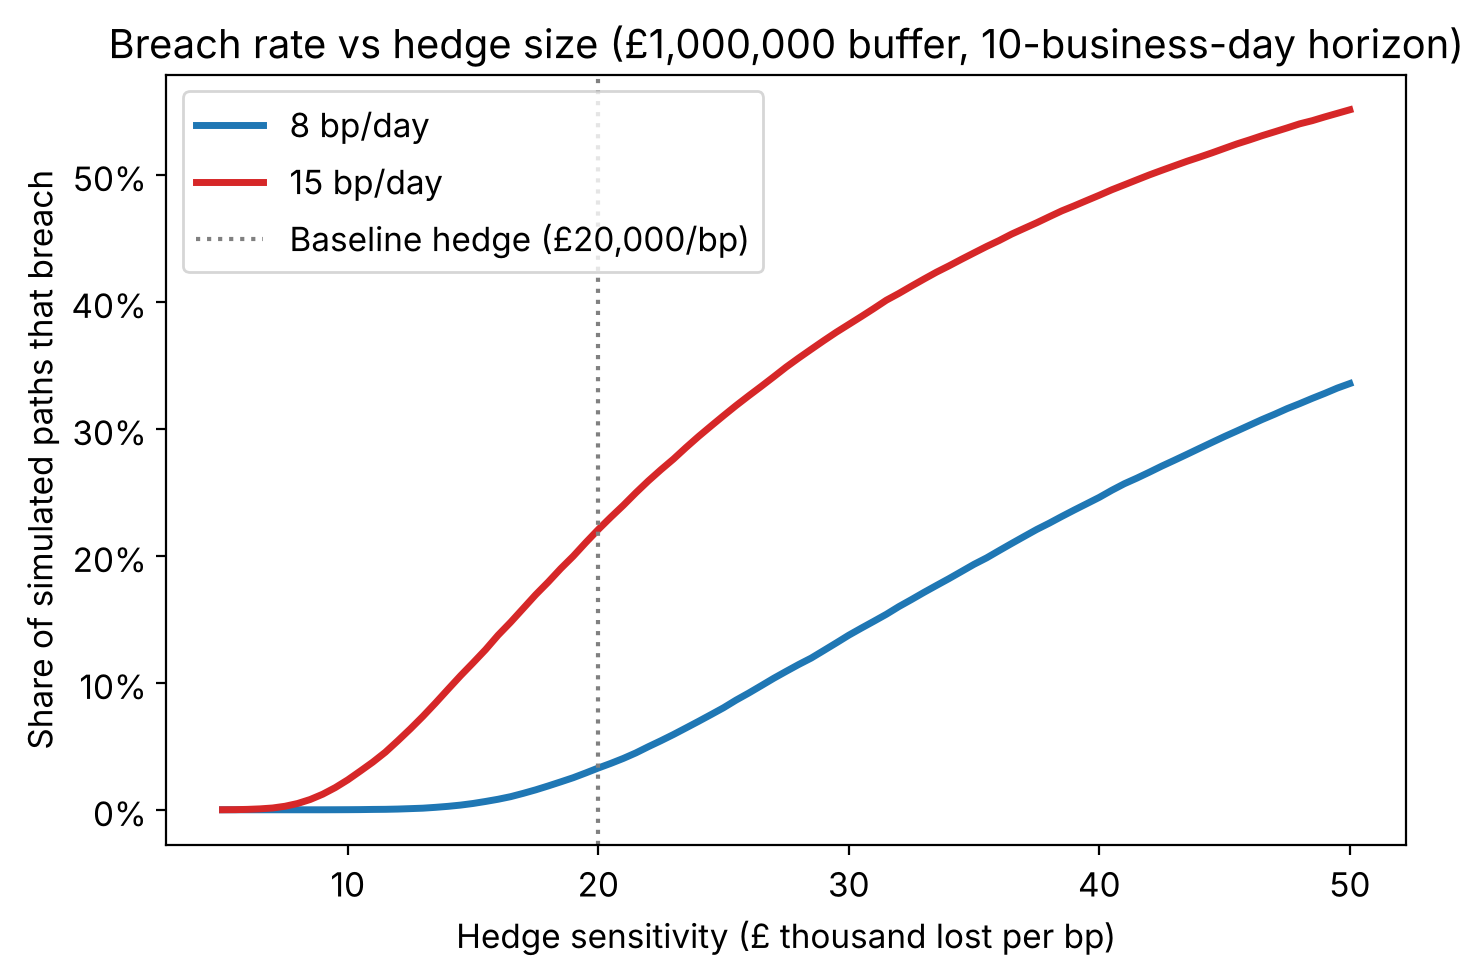

£0.5m buffer, £20k/bp hedge: 24.60%   |   £1m buffer, £40k/bp hedge: 24.60%


In [7]:
# Section 5: breach rate against hedge size, for the baseline £1m buffer (same shocks)
sens_values = np.linspace(5_000, 50_000, 91)
peak_base, peak_high = paths_base.max(axis=1), paths_high.max(axis=1)
rate_sens_base = [(collateral_required(peak_base, s) > BUFFER).mean() for s in sens_values]
rate_sens_high = [(collateral_required(peak_high, s) > BUFFER).mean() for s in sens_values]

fig, ax = plt.subplots()
ax.plot(sens_values / 1e3, rate_sens_base, lw=2.5, color='tab:blue', label=f'{SIGMA_BASE:.0f} bp/day')
ax.plot(sens_values / 1e3, rate_sens_high, lw=2.5, color='tab:red', label=f'{SIGMA_HIGH:.0f} bp/day')
ax.axvline(SENS / 1e3, color='grey', ls=':', label=f'Baseline hedge ({gbp(SENS)}/bp)')
ax.set_xlabel('Hedge sensitivity (£ thousand lost per bp)')
ax.set_ylabel('Share of simulated paths that breach')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title(f'Breach rate vs hedge size ({gbp(BUFFER)} buffer, {HORIZON}-business-day horizon)')
ax.legend()
plt.show()

# Doubling the hedge = halving the buffer: check on the same paths
r1 = summarise(paths_base, buffer=500_000, sens=SENS)['breach_rate']
r2 = summarise(paths_base, buffer=BUFFER, sens=2 * SENS)['breach_rate']
print(f'£0.5m buffer, £20k/bp hedge: {r1:.2%}   |   £1m buffer, £40k/bp hedge: {r2:.2%}')

## 6. Check the model and explain its limits

### Automated checks

In [8]:
# Section 6: model checks
# 1. Zero shocks produce zero shortfalls
zero_paths = simulate_paths(SIGMA_BASE, z=np.zeros((1000, HORIZON)))
assert np.all(max_shortfall_along_path(zero_paths) == 0)
print('Check 1 passed: zero yield shocks give zero shortfall.')

# 2. A larger cash buffer never increases breaches (or shortfalls) on the same paths
worst_by_buffer = np.column_stack([max_shortfall_along_path(paths_base, buffer=B) for B in buffers[::8]])
assert np.all(np.diff((worst_by_buffer > 0).astype(int), axis=1) <= 0)      # breach indicator non-increasing in B
assert np.all(np.diff(worst_by_buffer, axis=1) <= 0)          # shortfall size non-increasing in B
assert np.all(np.diff(rate_base) <= 0) and np.all(np.diff(rate_high) <= 0)
print('Check 2 passed: on every path, raising the buffer never adds a breach or increases the shortfall.')

# 3. The hand-worked example still holds when passed through the path machinery
paths_example = np.array([[0, 50, 50, 50],      # rises to exactly 50bp: buffer used up, no shortfall
                          [0, 60, 60, 60],      # rises to 60bp: £200,000 shortfall
                          [0, 30, 60, 0]])      # rises to 60bp then fully reverses: collateral returned
worst_example = max_shortfall_along_path(paths_example)
assert np.array_equal(worst_example, [0, 200_000, 200_000])
assert collateral_required(paths_example[2, -1]) == 0
print('Check 3 passed: 50bp -> £0 shortfall; 60bp -> £200,000; a reversed path still records its £200,000 peak '
      'and ends with all collateral returned.')

Check 1 passed: zero yield shocks give zero shortfall.
Check 2 passed: on every path, raising the buffer never adds a breach or increases the shortfall.
Check 3 passed: 50bp -> £0 shortfall; 60bp -> £200,000; a reversed path still records its £200,000 peak and ends with all collateral returned.


### Limits of the model

The simulated breach rate is a product of the assumptions, not a forecast. The most important assumptions are:

* **The yield-shock distribution.** Independent normal daily changes have thin tails and no memory. Real gilt markets have fat tails, volatility clustering (large moves follow large moves) and, in a crisis, momentum. Forced selling by funds that cannot meet collateral calls pushes yields up further, which creates more collateral calls. This feedback loop is exactly what drove September 2022, and the model leaves it out. The volatility number itself is hypothetical, and Section 5 shows the result is very sensitive to it.
* **The hedge's constant sensitivity.** The loss per basis point is held fixed at £20,000. In reality, sensitivity changes with the level of yields (convexity), with the fund's leverage, and as positions are rebalanced. Collateral rules also add haircuts, thresholds and timing details.
* **One yield, one horizon.** A single long-dated yield stands in for the whole curve, and inflation-linked exposure is ignored. Results depend on the 10-business-day horizon. Longer horizons give larger cumulative moves, while intraday calls could bite sooner than daily monitoring shows.
* **A static buffer.** The fund cannot raise cash by selling other assets, drawing on facilities or calling on its sponsor. These are real sources of liquidity, but each takes time and may be costly in a stressed market.
* **Liabilities are ignored.** The fund's solvency may improve as yields rise. The model is only about cash today.

## 7. Extension: replaying September 2022 through the same fund

To challenge the baseline distribution, we replay a period of large historical yield moves through the same hypothetical fund.

**Data.** Cumulative change in long-term gilt yields since 21 September 2022, from the crisis timeline in Chen & Kemp (2023), *Putting Out the NBFire: Lessons from the UK's Liability-Driven Investment (LDI) Crisis*, IMF Working Paper 23/210. The paper reports these as changes in "long-term gilt" yields and does not give a maturity for every figure. Its text describes the 30-year gilt for the 27 and 28 September moves. The timeline gives figures for consecutive business days from 21 to 28 September, which is the window replayed here. That is 5 business days, within the 10-day horizon used above. The fall on 28 September followed the Bank of England's announcement of temporary purchases of long-dated gilts.

In [9]:
# Section 7: historical replay of 21-28 September 2022 (cumulative change in long-term gilt yields, bp)
# Source: Chen & Kemp (2023), IMF WP/23/210, LDI crisis timeline (changes since 21 Sept 2022).
hist = pd.DataFrame({
    'date': pd.to_datetime(['2022-09-21', '2022-09-22', '2022-09-23', '2022-09-26', '2022-09-27', '2022-09-28']),
    'cum_change_bp': [0, 19, 27, 95, 140, 34],
})
hist['business_day'] = np.arange(len(hist))
hist['daily_change_bp'] = hist['cum_change_bp'].diff().fillna(0)
hist['collateral'] = collateral_required(hist['cum_change_bp'].values)
hist['shortfall'] = shortfall(hist['cum_change_bp'].values)

display(hist.assign(date=hist['date'].dt.strftime('%a %d %b'),
                    collateral=hist['collateral'].map(gbp),
                    shortfall=hist['shortfall'].map(gbp)).style.hide(axis='index'))

hist_peak = hist['cum_change_bp'].max()
hist_peak_day = int(hist.loc[hist['cum_change_bp'].idxmax(), 'business_day'])
print(f'Peak rise: {hist_peak} bp after {hist_peak_day} business days -> '
      f'peak shortfall {gbp(shortfall(hist_peak))} on a {gbp(BUFFER)} buffer')
print(f'Largest one-day rise: {hist["daily_change_bp"].max():.0f} bp '
      f'= {hist["daily_change_bp"].max() / SIGMA_BASE:.1f} baseline daily standard deviations')

date,cum_change_bp,business_day,daily_change_bp,collateral,shortfall
Wed 21 Sep,0,0,0.000000,£0,£0
Thu 22 Sep,19,1,19.000000,"£380,000",£0
Fri 23 Sep,27,2,8.000000,"£540,000",£0
Mon 26 Sep,95,3,68.000000,"£1,900,000","£900,000"
Tue 27 Sep,140,4,45.000000,"£2,800,000","£1,800,000"
Wed 28 Sep,34,5,-106.000000,"£680,000",£0


Peak rise: 140 bp after 4 business days -> peak shortfall £1,800,000 on a £1,000,000 buffer
Largest one-day rise: 68 bp = 8.5 baseline daily standard deviations


Baseline: paths reaching 140 bp within 4 days: 0 of 100,000; within 10 days: 0; largest simulated 10-day peak: 110 bp
High vol: paths reaching 140 bp within 4 days: 1 of 100,000; within 10 days: 179; largest simulated 10-day peak: 207 bp

Baseline normal model: P(4-day change >= 140 bp) ≈ 1.1e-18
Daily volatility needed for a 140 bp peak within 4 days to be a 1-in-100 outcome: 30 bp/day


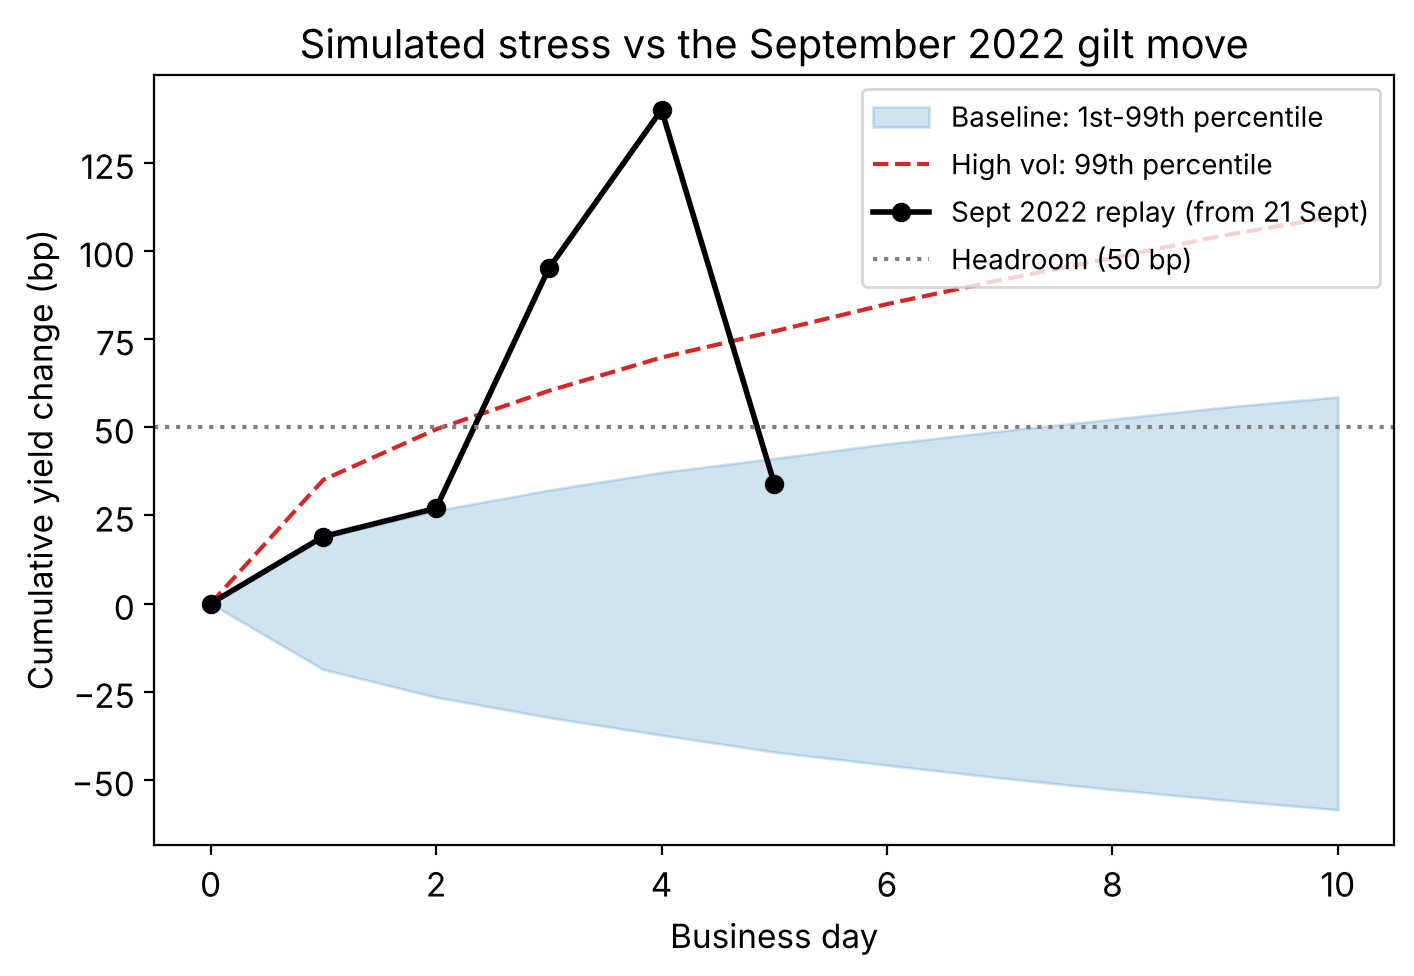

In [10]:
# Section 7: does the baseline model generate shocks of comparable size over the same horizon?
peak_first_k = lambda paths, k: paths[:, :k + 1].max(axis=1)     # max cumulative rise within k days

for label, paths in [('Baseline', paths_base), ('High vol', paths_high)]:
    pk4 = peak_first_k(paths, hist_peak_day)
    pk10 = paths.max(axis=1)
    print(f'{label}: paths reaching {hist_peak} bp within {hist_peak_day} days: {(pk4 >= hist_peak).sum()} of {N_PATHS:,}; '
          f'within {HORIZON} days: {(pk10 >= hist_peak).sum()}; largest simulated {HORIZON}-day peak: {pk10.max():.0f} bp')

# Normal-model probability of a rise of at least 140bp over 4 days, and the volatility that would make
# the historical move a 1-in-100 event over the 4-day window (peak scales linearly with sigma)
p_normal = norm.sf(hist_peak / (SIGMA_BASE * np.sqrt(hist_peak_day)))
unit_peak_4 = peak_first_k(simulate_paths(1.0), hist_peak_day)
sigma_needed = hist_peak / np.quantile(unit_peak_4, 0.99)
print(f'\nBaseline normal model: P(4-day change >= {hist_peak} bp) ≈ {p_normal:.1e}')
print(f'Daily volatility needed for a {hist_peak} bp peak within {hist_peak_day} days to be a 1-in-100 outcome: '
      f'{sigma_needed:.0f} bp/day')

fig, ax = plt.subplots()
pct = np.percentile(paths_base, [1, 50, 99], axis=0)
pct_h = np.percentile(paths_high, [99], axis=0)
ax.fill_between(days, pct[0], pct[2], color='tab:blue', alpha=0.2, label='Baseline: 1st-99th percentile')
ax.plot(days, pct_h[0], color='tab:red', ls='--', label='High vol: 99th percentile')
ax.plot(hist['business_day'], hist['cum_change_bp'], 'ko-', lw=2, label='Sept 2022 replay (from 21 Sept)')
ax.axhline(BUFFER / SENS, color='grey', ls=':', label=f'Headroom ({BUFFER / SENS:.0f} bp)')
ax.set_xlabel('Business day')
ax.set_ylabel('Cumulative yield change (bp)')
ax.set_title('Simulated stress vs the September 2022 gilt move')
ax.legend(loc='upper right', fontsize=10)
plt.show()

The replay is far outside what the baseline model generates. The fund's buffer is gone after the 26 September move, and at the 27 September peak it would have needed collateral **2.8 times** its buffer, a shortfall of £1.8m. None of the 100,000 baseline paths reaches a 140 bp rise within 4 business days; the largest baseline 10-day peak is about 110 bp. Only 1 of the 100,000 high-volatility paths does. Under independent normal shocks with $\sigma = 8$ bp/day, the move has a probability of about $10^{-18}$, so the model treats it as impossible. For it to be merely a 1-in-100 outcome, daily volatility would need to be about 30 bp/day, nearly four times the baseline. The single-day move on 26 September alone was more than 8 baseline standard deviations.

The lesson is about the assumptions, not the arithmetic. A model calibrated to normal-times volatility, with thin tails and no feedback, can report a small breach rate for a buffer that a real stress would exhaust within days. Sensible next steps would be fat-tailed shocks (for example Student-*t*), volatility that rises after large moves, a feedback term in which shortfalls trigger selling that raises yields, and calibration to a long history of daily gilt yields such as the Bank of England's published yield curve data.

## Conclusion

* **First milestone:** the model reproduces the hand-worked example exactly. A 50 bp rise uses up the £1m buffer, and a 60 bp rise leaves a £200,000 shortfall.
* **Baseline (8 bp/day, 10 business days):** 3.3% of simulated paths breach the £1m buffer at some point, with a median shortfall of about £135,000 when they do. Measuring only at the end of the horizon would miss about a quarter of these breaches.
* **What changed the result most was the volatility assumption.** Moving from 8 to 15 bp/day raises the breach rate from 3.3% to 22% over the same 10-day horizon, and the buffer needed for a given breach rate scales roughly in proportion to volatility. Buffer size and hedge size matter only through their ratio, the headroom in basis points.
* **The historical replay** shows that the normal baseline badly understates tail risk. The September 2022 move would have produced a £1.8m shortfall for this fund within 4 business days, a move the baseline model essentially never generates. Any conclusion about how much cash is "enough" depends heavily on the shock distribution.